<a href="https://colab.research.google.com/github/leandrolaune/CRUD-tabela-de-produtos-Python-SQL/blob/master/CONVNEXTTINY_Classifica%C3%A7%C3%A3o_de_doen%C3%A7as_em_planta%C3%A7%C3%B5es_de_arroz.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Importando bibliotecas
import torch
import torchvision
import torchvision.transforms as transforms
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models
from torch.utils.data import DataLoader

from sklearn.metrics import classification_report, confusion_matrix

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import os

from google.colab import drive

In [ ]:
#Função Early Stopping
class EarlyStopping:
  def __init__(self, patience=5, min_delta=0):
    self.patience = patience
    self.min_delta = min_delta
    self.best_loss = float('inf')
    self.counter = 0

  def __call__(self, val_loss):
    if val_loss < self.best_loss - self.min_delta:
      self.best_loss = val_loss
      self.counter = 0
    else:
      self.counter += 1
      if self.counter >= self.patience:
        print('Early stopping ativado!')
        return True
    return False

In [ ]:
import kagglehub
import os

path = kagglehub.dataset_download("felipeguimaraess/doencas-no-arroz")

print("Dataset path:", path)

base_dir = os.path.join(path, "doencas_arroz_dataset")

train_dir = os.path.join(base_dir, "treino")
val_dir = os.path.join(base_dir, "validacao")
test_dir = os.path.join(base_dir, "teste")

print("Train:", train_dir)
print("Val:", val_dir)
print("Test:", test_dir)

Using Colab cache for faster access to the 'doencas-no-arroz' dataset.
Dataset path: /kaggle/input/doencas-no-arroz
Train: /kaggle/input/doencas-no-arroz/doencas_arroz_dataset/treino
Val: /kaggle/input/doencas-no-arroz/doencas_arroz_dataset/validacao
Test: /kaggle/input/doencas-no-arroz/doencas_arroz_dataset/teste


In [ ]:
# Data augmentation (somente treino)
train_transforms = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

# Validação e teste SEM augmentation
val_test_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

batch_size = 32

# Carregando datasets
trainset = torchvision.datasets.ImageFolder(root=train_dir, transform=train_transforms)
valset = torchvision.datasets.ImageFolder(root=val_dir, transform=val_test_transforms)
testset = torchvision.datasets.ImageFolder(root=test_dir, transform=val_test_transforms)

classes = trainset.classes
print(f"Classes encontradas: {classes}")

print(f"\nResumo da Divisão:")
print(f"--- Treino: {len(trainset)}")
print(f"--- Validação: {len(valset)}")
print(f"--- Teste: {len(testset)}")

# =========================
# 🔥 BALANCEAMENTO
# =========================
from collections import Counter
from torch.utils.data import WeightedRandomSampler

labels = [label for _, label in trainset]
class_counts = Counter(labels)

print("\nDistribuição das classes no treino:")
print(class_counts)

# Peso inverso à frequência
class_weights = {cls: 1.0/count for cls, count in class_counts.items()}

# Peso para cada amostra
sample_weights = [class_weights[label] for label in labels]

sampler = WeightedRandomSampler(
    sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

# =========================
# DataLoaders
# =========================
trainloader = DataLoader(trainset, batch_size=batch_size, sampler=sampler, num_workers=2)

valloader = DataLoader(valset, batch_size=batch_size, shuffle=False, num_workers=2)
testloader = DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=2)

Classes encontradas: ['brusone', 'escaldura', 'mancha_parda', 'queima_bacteriana', 'queima_da_bainha', 'saudavel']

Resumo da Divisão:
--- Treino: 6550
--- Validação: 1405
--- Teste: 1405

Distribuição das classes no treino:
Counter({1: 1168, 2: 1120, 3: 1108, 4: 1104, 5: 1042, 0: 1008})


In [ ]:
# Carregando ConvNeXt Tiny com pesos pré-treinados
pesos = models.ConvNeXt_Tiny_Weights.DEFAULT
model = models.convnext_tiny(weights=pesos)

# Congelar pesos
for parametros in model.parameters():
    parametros.requires_grad = False

# Ajustar camada final
num_ftrs = model.classifier[2].in_features
model.classifier[2] = nn.Linear(num_ftrs, len(classes))

# GPU ou CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# Contagem de parâmetros
total_parametros = sum(p.numel() for p in model.parameters())
parametros_treinaveis = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Número total de parâmetros: {total_parametros:,}")
print(f"Número de parâmetros treináveis: {parametros_treinaveis:,}")

Número total de parâmetros: 27,824,742
Número de parâmetros treináveis: 4,614


In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.classifier[2].parameters(), lr=0.001)

In [ ]:
num_epochs = 100
early_stopping = EarlyStopping(patience=5, min_delta=0.001)

train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []

for epoch in range(num_epochs):

    print(f"\nÉpoca {epoch+1}/{num_epochs}")

    model.train()
    running_loss, correct_train, total_train = 0.0, 0, 0

    for inputs, labels in tqdm(trainloader, desc="Treinando"):
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    train_loss = running_loss / len(trainloader)
    train_acc = 100 * correct_train / total_train
    train_losses.append(train_loss)
    train_accuracies.append(train_acc)

    model.eval()
    val_loss, correct_val, total_val = 0.0, 0, 0

    with torch.no_grad():
        for inputs, labels in tqdm(valloader, desc="Validando"):
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            val_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()

    val_loss /= len(valloader)
    val_acc = 100 * correct_val / total_val
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print(f"Perda: {train_loss:.4f} | Val_Loss: {val_loss:.4f} | Acc: {train_acc:.2f}% | Val_Acc: {val_acc:.2f}%")

    if early_stopping(val_loss):
        print("\nEarly Stopping ativado!")
        break

print('\nTreinamento finalizado!')


Época 1/100


Validando: 100%|██████████| 44/44 [00:38<00:00,  1.16it/s]


Perda: 0.4779 | Val_Loss: 0.2132 | Acc: 86.75% | Val_Acc: 94.80%

Época 2/100


Validando: 100%|██████████| 44/44 [00:33<00:00,  1.31it/s]


Perda: 0.2238 | Val_Loss: 0.1509 | Acc: 93.24% | Val_Acc: 96.44%

Época 3/100


Validando: 100%|██████████| 44/44 [00:32<00:00,  1.34it/s]


... (55 outputs left out)

Validando: 100%|██████████| 44/44 [00:32<00:00,  1.36it/s]


Perda: 0.0642 | Val_Loss: 0.0260 | Acc: 97.97% | Val_Acc: 99.36%

Época 32/100


Validando: 100%|██████████| 44/44 [00:34<00:00,  1.28it/s]

Perda: 0.0626 | Val_Loss: 0.0242 | Acc: 97.86% | Val_Acc: 99.50%
Early stopping ativado!

Early Stopping ativado!

Treinamento finalizado!


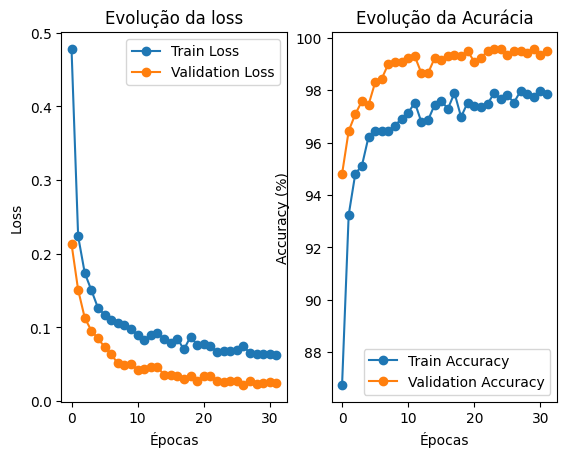

In [ ]:
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss', marker='o')
plt.plot(val_losses, label='Validation Loss', marker='o')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.title('Evolução da loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label='Train Accuracy', marker='o')
plt.plot(val_accuracies, label='Validation Accuracy', marker='o')
plt.xlabel('Épocas')
plt.ylabel('Accuracy (%)')
plt.title('Evolução da Acurácia')
plt.legend()

plt.show()

In [ ]:
model.eval()

all_preds = []
all_labels = []

print("Iniciando avaliação final no conjunto de TESTE (inédito)...")

with torch.no_grad():
    for inputs, labels in testloader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = model(inputs)
        _, predicted = torch.max(outputs, 1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

class_names = trainset.classes

print("\n--- Relatório de Métricas (Test Set) ---")
relatorio = classification_report(all_labels, all_preds, target_names=class_names, digits=4)
print(relatorio)

matriz_confusao = confusion_matrix(all_labels, all_preds)

Iniciando avaliação final no conjunto de TESTE (inédito)...

--- Relatório de Métricas (Test Set) ---
                   precision    recall  f1-score   support

          brusone     1.0000    0.9954    0.9977       216
        escaldura     0.9881    0.9960    0.9921       251
     mancha_parda     0.9959    1.0000    0.9979       240
queima_bacteriana     1.0000    1.0000    1.0000       238
 queima_da_bainha     0.9957    0.9873    0.9915       237
         saudavel     1.0000    1.0000    1.0000       223

         accuracy                         0.9964      1405
        macro avg     0.9966    0.9965    0.9965      1405
     weighted avg     0.9965    0.9964    0.9964      1405



In [ ]:
model.eval()

all_preds = []
all_labels = []

print("Iniciando avaliação final no conjunto de TESTE (inédito)...")

with torch.no_grad():
    for inputs, labels in testloader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = model(inputs)
        _, predicted = torch.max(outputs, 1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

class_names = trainset.classes

print("\n--- Relatório de Métricas (Test Set) ---")
relatorio = classification_report(all_labels, all_preds, target_names=class_names, digits=4)
print(relatorio)

matriz_confusao = confusion_matrix(all_labels, all_preds)

Iniciando avaliação final no conjunto de TESTE (inédito)...

--- Relatório de Métricas (Test Set) ---
                   precision    recall  f1-score   support

          brusone     1.0000    0.9954    0.9977       216
        escaldura     0.9881    0.9960    0.9921       251
     mancha_parda     0.9959    1.0000    0.9979       240
queima_bacteriana     1.0000    1.0000    1.0000       238
 queima_da_bainha     0.9957    0.9873    0.9915       237
         saudavel     1.0000    1.0000    1.0000       223

         accuracy                         0.9964      1405
        macro avg     0.9966    0.9965    0.9965      1405
     weighted avg     0.9965    0.9964    0.9964      1405



In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

acc = accuracy_score(all_labels, all_preds)
prec = precision_score(all_labels, all_preds, average='macro')
rec = recall_score(all_labels, all_preds, average='macro')
f1 = f1_score(all_labels, all_preds, average='macro')

print("\n=== 📊 MÉTRICAS GERAIS ===")
print(f"Acurácia: {acc:.4f}")
print(f"Precisão (macro): {prec:.4f}")
print(f"Recall (macro): {rec:.4f}")
print(f"F1-score (macro): {f1:.4f}")


=== 📊 MÉTRICAS GERAIS ===
Acurácia: 0.9964
Precisão (macro): 0.9966
Recall (macro): 0.9965
F1-score (macro): 0.9965


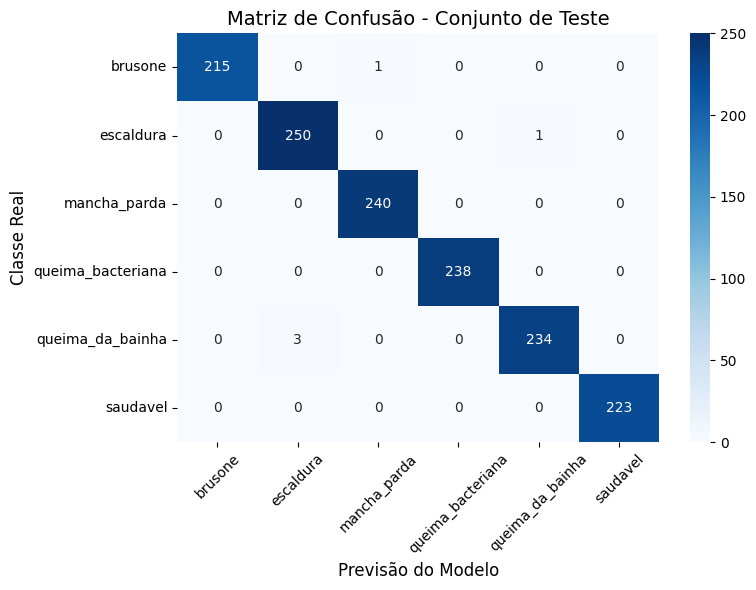

In [ ]:
plt.figure(figsize=(8, 6))

sns.heatmap(matriz_confusao, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)

plt.xlabel('Previsão do Modelo', fontsize=12)
plt.ylabel('Classe Real', fontsize=12)
plt.title('Matriz de Confusão - Conjunto de Teste', fontsize=14)

plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()